# Week 9 — Exercise: Cell types from single-cell RNA-seq

**27200 Data-driven Bioengineering**

We use a classic public dataset: **2,638 peripheral blood mononuclear cells (PBMCs)** from a healthy donor,
measured by single-cell RNA sequencing (10x Genomics). Each cell has been assigned to one of eight immune
cell types:

| Cell type | Marker genes | What it is |
|---|---|---|
| CD4 T cells | `IL7R`, `CD3E` | helper T cells, coordinate the immune response |
| CD8 T cells | `CD8A`, `CD3E` | cytotoxic T cells, kill infected cells |
| NK cells | `GNLY`, `NKG7` | natural killer cells, innate cytotoxic cells |
| B cells | `MS4A1`, `CD79A` | produce antibodies |
| CD14+ Monocytes | `CD14`, `LYZ` | classical monocytes |
| FCGR3A+ Monocytes | `FCGR3A`, `MS4A7` | non-classical monocytes |
| Dendritic cells | `FCER1A`, `CST3` | present antigens to T cells |
| Megakaryocytes | `PPBP` | platelet precursors |

In the TCGA exercise we cleaned the data ourselves. Here we start from a matrix that has **already been
cleaned** in the same way: counts normalized per cell, log-transformed, reduced to the highly variable genes
and scaled per gene.

Run the cells in order. Questions are marked **Question x.y**; answer them in the text cells or discuss them
in your group.

In [243]:
!pip install -q scanpy umap-learn seaborn          # only needed the first time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import umap

from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, balanced_accuracy_score, ConfusionMatrixDisplay

# plot style, and a fixed random seed so that everyone gets the same results
sns.set_style("ticks")
plt.rcParams["figure.dpi"] = 600
SEED = 27200
PALETTE = [  # colour gradient used for single-colour plots
    "#b7094c", "#a01a58", "#892b64", "#723c70", "#5c4d7d", "#455e89", "#2e6f95", "#1780a1", "#0091ad"]
# the eight cell types, in the order used in all plots, and one colour per cell type
CELL_TYPES = ["CD4 T cells", "CD8 T cells", "NK cells", "B cells", "CD14+ Monocytes", "FCGR3A+ Monocytes",
              "Dendritic cells", "Megakaryocytes"]
COLOURS = dict(zip(CELL_TYPES, ["#0072B2", "#56B4E9", "#009E73", "#E69F00", "#D55E00", "#CC79A7", "#F0E442",
                                "#000000"]))   # distinct, colour-blind-safe (Okabe-Ito)

## 0 - Load the data

The cleaned dataset comes with Scanpy (from its "Preprocessing and clustering 3k PBMCs" tutorial).
`X` is the feature matrix we work with. For plotting marker genes we also keep the log-normalized
expression of all genes (before gene selection and scaling).

In [244]:
adata = sc.datasets.pbmc3k_processed()                        # downloads the dataset the first time (~25 MB)
X = np.asarray(adata.X, dtype=np.float32)                     # feature matrix: cells x highly variable genes (cleaned)
genes = adata.var_names                                       # gene names of the columns of X
cell_type = adata.obs["louvain"].astype(str).rename("cell_type")   # the annotated cell type of every cell
log_expr = adata.raw.to_adata().to_df()                       # log-normalized expression of all genes (for plots)
print("feature matrix:", X.shape, "(cells x genes)")

feature matrix: (2638, 1838) (cells x genes)


## 1 - Inspect the data

2638 cells, 1838 highly variable genes (of 13714 detected)
average mean per gene: -0.00, average standard deviation per gene: 0.92


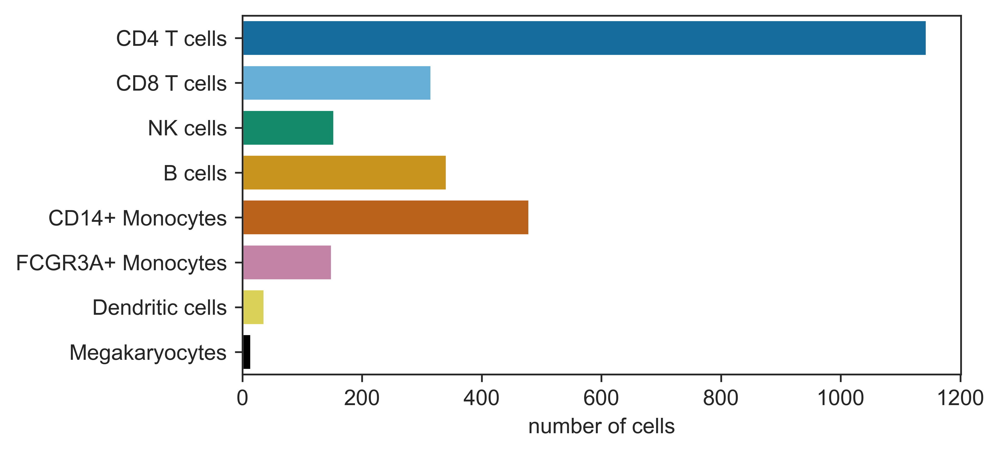

In [245]:
# size of the data, and a check that the genes are scaled (mean 0 and standard deviation ~1 per gene)
print(f"{X.shape[0]} cells, {X.shape[1]} highly variable genes (of {log_expr.shape[1]} detected)")
print(f"average mean per gene: {X.mean(axis=0).mean():.2f}, average standard deviation per gene: {X.std(axis=0).mean():.2f}")

# number of cells per cell type
fig, ax = plt.subplots(figsize=(6.5, 3))
sns.countplot(y=cell_type, order=CELL_TYPES, hue=cell_type, palette=COLOURS, ax=ax)
ax.set(xlabel="number of cells", ylabel="")
plt.tight_layout(); plt.show()

**Question 1.1** Is the dataset balanced? Which cell types are the least frequent? What complications could
this cause for classification models?

*Your answer:*

## 2 - The cells in PCA and UMAP space

UMAP builds a neighbour graph and lays it out in two dimensions. As in the TCGA exercise, we run it on the
first principal components rather than on all genes.

/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


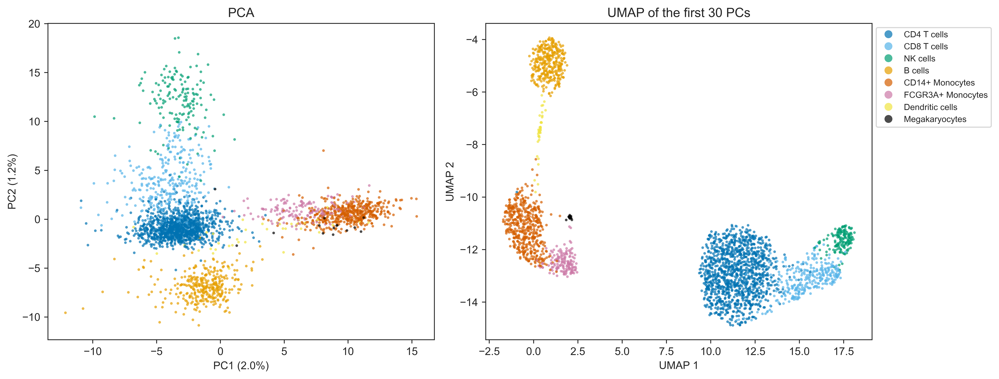

In [246]:
# PCA: project the cells onto the 50 directions of largest variance
pca = PCA(n_components=50, random_state=SEED)
scores = pca.fit_transform(X)                     # PC scores: cells x 50 components
evr = pca.explained_variance_ratio_               # fraction of the variance per component

# UMAP: a 2D embedding computed from the first N_PCS principal components
N_PCS = 30
emb = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=SEED).fit_transform(scores[:, :N_PCS])

# left: PC1 vs PC2; right: UMAP; both coloured by the annotated cell type
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=cell_type, hue_order=CELL_TYPES, palette=COLOURS,
                s=6, alpha=0.7, linewidth=0, legend=False, ax=ax[0])
ax[0].set(xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})", title="PCA")
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=cell_type, hue_order=CELL_TYPES, palette=COLOURS,
                s=6, alpha=0.7, linewidth=0, ax=ax[1])
ax[1].set(xlabel="UMAP 1", ylabel="UMAP 2", title=f"UMAP of the first {N_PCS} PCs")
ax[1].legend(markerscale=3, title=None, fontsize=8, bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Question 2.1** What is the fundamental difference that makes UMAP better at visualizing single-cell data than
PCA? How do the distances between cell types differ between the two plots? Which one represents the global
distances between the cell types more accurately?

*Your answer:*

## 3 - Cell type classification

#### Logistic regression and class imbalance

We start with a logistic regression on all genes, trained on 80 % of the cells and tested on the other 20 %.
The cell types are very unbalanced (1,144 CD4 T cells, but only 15 megakaryocytes). We train two versions:

- **Unbalanced** (`class_weight=None`, the default): every cell counts equally in the loss, so the large cell
  types dominate the training.
- **Balanced** (`class_weight="balanced"`): each cell is weighted by 1 / (number of cells of its type), so every
  cell type counts equally in the loss.

We report two scores: the **overall accuracy** (fraction of all test cells predicted correctly) and the
**cell-type averaged accuracy** (the recall of each cell type, averaged over the eight types; in scikit-learn
this is called `balanced_accuracy_score`).

Unbalanced  overall accuracy 0.941   cell-type averaged 0.856
Balanced    overall accuracy 0.962   cell-type averaged 0.964


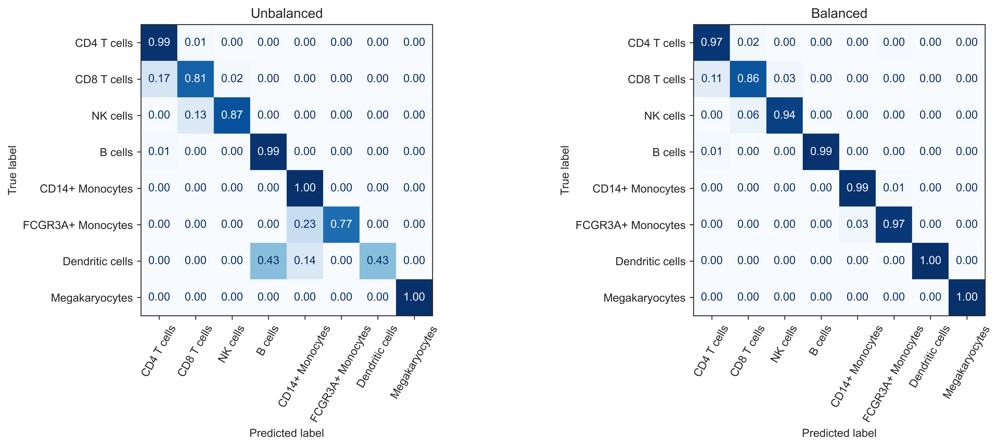

In [247]:
# labels, and an 80/20 split of the cells; stratify=y keeps the cell-type proportions the same in both parts
y = cell_type.to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
C = 0.01                                          # regularization strength: smaller C = stronger (try 1, 0.01, 0.001)

# unbalanced model: class_weight=None (the default), every cell has weight 1,
# so the large cell types dominate the loss
model_unbalanced = LogisticRegression(C=C, class_weight=None, max_iter=2000)
pred_unbalanced = model_unbalanced.fit(X_train, y_train).predict(X_test)   # fit on the training cells, predict the test cells

# balanced model: the only change is class_weight="balanced"
model_balanced = LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
pred_balanced = model_balanced.fit(X_train, y_train).predict(X_test)

# overall accuracy: fraction of all test cells correct (dominated by the large cell types)
# cell-type averaged accuracy: the recall of each cell type, averaged (every cell type counts equally)
for name, pred in [("Unbalanced", pred_unbalanced), ("Balanced", pred_balanced)]:
    print(f"{name:11} overall accuracy {accuracy_score(y_test, pred):.3f}   "
          f"cell-type averaged {balanced_accuracy_score(y_test, pred):.3f}")

# confusion matrices, normalized per row: each row shows where the test cells of one true type ended up
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6))
for a, pred, title in [(ax[0], pred_unbalanced, "Unbalanced"), (ax[1], pred_balanced, "Balanced")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CELL_TYPES, normalize="true", values_format=".2f",
                                            cmap="Blues", ax=a, colorbar=False, xticks_rotation=60)
    a.set_title(title)
plt.tight_layout(); plt.show()

**Question 3.1** Which cell types does the unbalanced model predict poorly compared to the others? What could
be the reasons?

*Your answer:*

**Question 3.2** Why does balancing the training data improve the logistic regression?

*Your answer:*

**Question 3.3** Megakaryocytes are rarer than dendritic cells. Why are they still predicted accurately by both
the balanced and the unbalanced model?

*Your answer:*

#### Comparing classifiers

We now train three other classifiers. To compare them fairly, all use the 1,000 genes that differ most between
the cell types, selected with an F-test **inside the pipeline**, so that the selection is refitted on the
training data only and never sees the test cells.

In [248]:
# 5-fold cross-validation on the training cells: train on 4/5, evaluate on the remaining 1/5, five times
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def select():
    # keep the 1,000 genes with the largest F-statistic between the cell types
    return SelectKBest(f_classif, k=1000)

# each model is a pipeline: first gene selection, then the classifier
models = {
    "LDA": make_pipeline(select(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
    "SVM": make_pipeline(select(), SVC(kernel="rbf", C=1.0, class_weight="balanced")),
    "Random forest": make_pipeline(select(), RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                                    n_jobs=-1, random_state=SEED)),
}
print("Cross-validation on the training data:")
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring="balanced_accuracy")
    print(f"{name:14} cell-type averaged accuracy {r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")

Cross-validation on the training data:
LDA            cell-type averaged accuracy 0.917 ± 0.034
SVM            cell-type averaged accuracy 0.762 ± 0.034
Random forest  cell-type averaged accuracy 0.818 ± 0.014


Test data:
LDA            overall accuracy 0.951   cell-type averaged 0.951
SVM            overall accuracy 0.947   cell-type averaged 0.755
Random forest  overall accuracy 0.920   cell-type averaged 0.845





In [249]:
# train each model on all training cells, evaluate on the test cells, and show the confusion matrices
# (normalized per row, in the same style as for the logistic regression above)
fig, ax = plt.subplots(1, 3, figsize=(21, 5.6))
print("Test data:")
for a, (name, model) in zip(ax, models.items()):
    pred = model.fit(X_train, y_train).predict(X_test)
    print(f"{name:14} overall accuracy {accuracy_score(y_test, pred):.3f}   "
          f"cell-type averaged {balanced_accuracy_score(y_test, pred):.3f}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CELL_TYPES, normalize="true", values_format=".2f",
                                            cmap="Blues", ax=a, colorbar=False, xticks_rotation=60)
    a.set_title(name)
plt.tight_layout(); plt.show()

**Question 3.4** Why do we split the data into training and test sets?

*Your answer:*

**Question 3.5** How do the models compare? Which cell types are confused? Which model would you choose as the
best cell type classifier?

*Your answer:*

**Question 3.6** The logistic regression predicted the megakaryocytes accurately. Why does the SVM assign them
to another cell type? Tip: try changing the kernel from `"rbf"` to `"linear"`.

*Your answer:*

## 4 - Feature inspection: what is the model looking at?

A good accuracy does not tell us *why* a model works. Here we look inside two models.

**Logistic regression** learns one weight (coefficient) per gene **for each cell type**. A large positive
weight means that high expression of this gene makes this cell type more likely; a negative weight means the
opposite. Because every gene was scaled to mean 0 and variance 1, the weights of different genes can be
compared directly.

**Random forest** gives a single **feature importance** per gene for the whole model: how much the splits on
that gene improved the purity of the tree nodes, summed over all trees. It is never negative, and it is not
specific to a cell type.

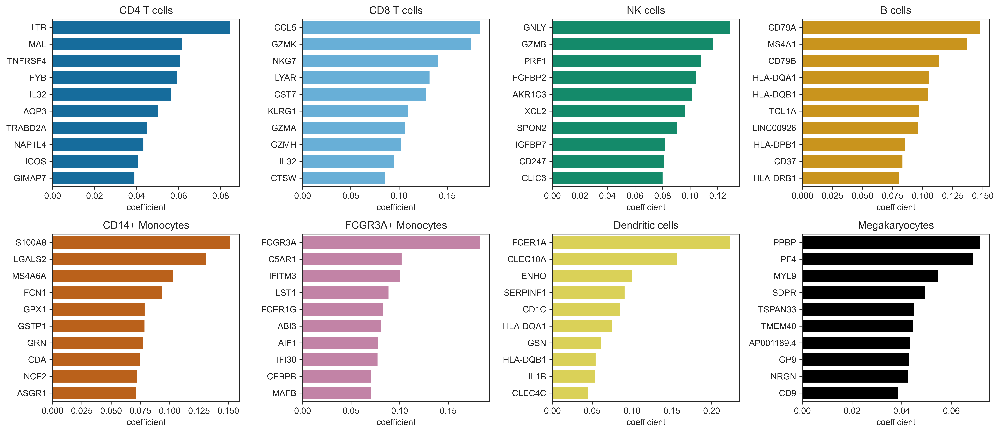

In [250]:
# coefficients of the balanced logistic regression: one row per cell type, one column per gene
coef = pd.DataFrame(model_balanced.coef_, index=model_balanced.classes_, columns=genes)

# for each cell type: the 10 genes with the largest positive weight
N_TOP = 10
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, t in zip(ax.ravel(), CELL_TYPES):
    top = coef.loc[t].nlargest(N_TOP)
    sns.barplot(x=top.values, y=top.index, color=COLOURS[t], ax=a)
    a.set(title=t, xlabel="coefficient", ylabel="")
plt.tight_layout(); plt.show()

**Question 4.1** How would you "sanity check" that the most important genes match the known biology of the
different cell types?

*Your answer:*

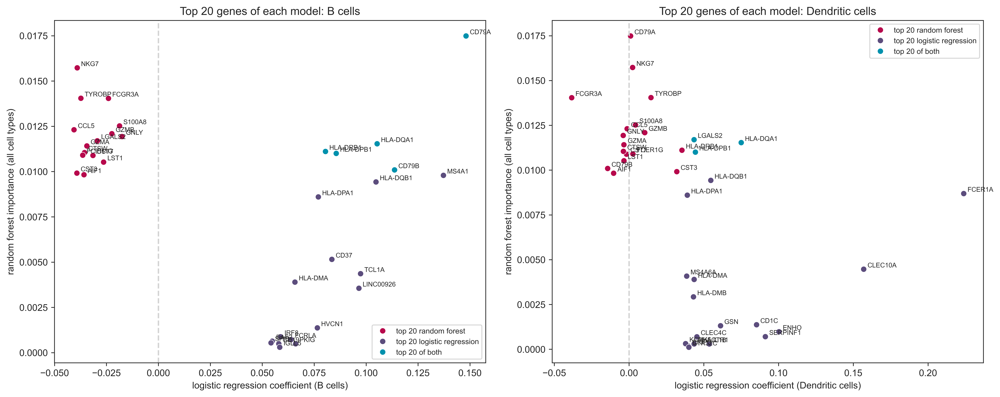

In [251]:
# random forest on all genes (no gene selection), so that every gene gets an importance
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
rf_imp = pd.Series(rf.feature_importances_, index=genes)     # one importance per gene, for all cell types together
top_rf = rf_imp.nlargest(20).index

# compare the random forest importance with the logistic regression coefficient for B cells and dendritic cells,
# for the genes in the top 20 of either model
groups = {"top 20 random forest": PALETTE[0], "top 20 logistic regression": PALETTE[4], "top 20 of both": PALETTE[8]}
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, t in zip(ax, ["B cells", "Dendritic cells"]):
    lr_coef = coef.loc[t]                                    # logistic regression weights for this cell type
    top_lr = lr_coef.nlargest(20).index
    sel = top_rf.union(top_lr)                               # genes in the top 20 of either model
    group = pd.Series("top 20 logistic regression", index=sel)
    group[sel.isin(top_rf)] = "top 20 random forest"
    group[sel.isin(top_rf) & sel.isin(top_lr)] = "top 20 of both"

    sns.scatterplot(x=lr_coef[sel], y=rf_imp[sel], hue=group, hue_order=list(groups), palette=groups, s=40, ax=a)
    for g in sel:                                            # label every point with its gene name
        a.annotate(g, (lr_coef[g], rf_imp[g]), xytext=(4, 2), textcoords="offset points", fontsize=7)
    a.axvline(0, color="lightgrey", linestyle="--")          # left of this line: negative weight for this cell type
    a.set(xlabel=f"logistic regression coefficient ({t})", ylabel="random forest importance (all cell types)",
          title=f"Top 20 genes of each model: {t}")
    a.legend(title=None, fontsize=8)
plt.tight_layout(); plt.show()

**Question 4.2** Do both models use the same genes to identify B cells? How could you evaluate which set of
genes is better for predicting the cell type? What is the major difference between the importance reported by
the random forest and the coefficients of the logistic regression? Tip: look at the UMAP plots below.

*Your answer:*

In [252]:
# UMAP coloured by the expression of the top 10 genes of the random forest (all cell types, rows 1-2)
# and the top 10 genes of the logistic regression for one cell type (rows 3-4); genes in both lists are marked
t = "B cells"                                                # change to e.g. "Dendritic cells"
top_rf10 = rf_imp.nlargest(10).index
top_lr10 = coef.loc[t].nlargest(10).index
shared = set(top_rf10) & set(top_lr10)
panels = [(g, "RF") for g in top_rf10] + [(g, f"LR {t}") for g in top_lr10]

cmap = sns.blend_palette(["lightgrey", PALETTE[0]], as_cmap=True)   # grey = not expressed, dark red = high
fig, ax = plt.subplots(4, 5, figsize=(16, 13))
for a, (g, label) in zip(ax.ravel(), panels):
    x = log_expr[g].to_numpy()
    order = np.argsort(x)                                    # draw the expressing cells on top
    sns.scatterplot(x=emb[order, 0], y=emb[order, 1], hue=x[order], palette=cmap, hue_norm=(0, max(x.max(), 1)),
                    s=3, linewidth=0, legend=False, ax=a)
    a.set(xticks=[], yticks=[])
    if g in shared:                                          # in the top 10 of both models: coloured frame and tag
        a.set_title(f"{g} ({label}) ★ both", color=PALETTE[8], fontweight="bold")
        for spine in a.spines.values():
            spine.set(color=PALETTE[8], linewidth=2.5)
    else:
        a.set_title(f"{g} ({label})")
plt.tight_layout(); plt.show()
print("in the top 10 of both:", ", ".join(sorted(shared)) or "none")

/var/folders/fk/ycgfqq1520l3t9l7gs4wsjyr0000gp/T/ipykernel_24945/3196659250.py:23: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


in the top 10 of both: CD79A, HLA-DQA1


**Question 4.3** Here we used scRNA-seq data. In the future, we would like to use a much cheaper assay that
measures only the key markers needed to define a cell type. You saw that the models can choose different genes
to identify the cell types, and that there is a lot of collinearity in the data. What statistical framework
could we use to select a set of 10–20 markers for future use?

*Your answer:*